# Loan Management System with Intergrated Loan Risk Analysis

DATASET: Loan_approval_data_2025.csv

DESCRIPTION:
This project builds a machine learning model to predict loan approval outcomes based on demographic, financial, and loan-related features.

### Important Component of Dataset

Demographic:
- age
- occupation_status
- years_employed
  
Financial:
- annual_income
- credit_score
- savings_assets
- current_debt
- delinquencies_last_2yrs
- number_of_credit_accounts

Loan:
- loan_type
- loan_intent
- loan_amount
- interest_rate
- debt_to_income_ratio
- loan_to_income_ratio
- payment_to_income_ratio

Target Variable:
- loan_status (0 = default/rejected, 1 = approved)

## Data Preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Loan_approval_data_2025.csv")

In [3]:
df.head()

,customer_id,age,occupation_status,years_employed,annual_income,credit_score,credit_history_years,savings_assets,current_debt,defaults_on_file,delinquencies_last_2yrs,derogatory_marks,product_type,loan_intent,loan_amount,interest_rate,debt_to_income_ratio,loan_to_income_ratio,payment_to_income_ratio,loan_status
0,CUST100000,40,Employed,17.2,25579,692,5.3,895,10820,0,0,0,Credit Card,Business,600,17.02,0.423,0.023,0.008,1
1,CUST100001,33,Employed,7.3,43087,627,3.5,169,16550,0,1,0,Personal Loan,Home Improvement,53300,14.10,0.384,1.237,0.412,0
2,CUST100002,42,Student,1.1,20840,689,8.4,17,7852,0,0,0,Credit Card,Debt Consolidation,2100,18.33,0.377,0.101,0.034,1
3,CUST100003,53,Student,0.5,29147,692,9.8,1480,11603,0,1,0,Credit Card,Business,2900,18.74,0.398,0.099,0.033,1
4,CUST100004,32,Employed,12.5,63657,630,7.2,209,12424,0,0,0,Personal Loan,Education,99600,13.92,0.195,1.565,0.522,1


In [4]:
df.shape

(50000, 20)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              50000 non-null  object 
 1   age                      50000 non-null  int64  
 2   occupation_status        50000 non-null  object 
 3   years_employed           50000 non-null  float64
 4   annual_income            50000 non-null  int64  
 5   credit_score             50000 non-null  int64  
 6   credit_history_years     50000 non-null  float64
 7   savings_assets           50000 non-null  int64  
 8   current_debt             50000 non-null  int64  
 9   defaults_on_file         50000 non-null  int64  
 10  delinquencies_last_2yrs  50000 non-null  int64  
 11  derogatory_marks         50000 non-null  int64  
 12  product_type             50000 non-null  object 
 13  loan_intent              50000 non-null  object 
 14  loan_amount           

In [6]:
df = df.drop("customer_id", axis = 1)

## EDA

In [7]:
df.describe()

,age,years_employed,annual_income,credit_score,credit_history_years,savings_assets,current_debt,defaults_on_file,delinquencies_last_2yrs,derogatory_marks,loan_amount,interest_rate,debt_to_income_ratio,loan_to_income_ratio,payment_to_income_ratio,loan_status
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,34.957060,7.454868,50062.892040,643.614820,8.168274,3595.619400,14290.442220,0.053480,0.55464,0.147640,33041.874000,15.498591,0.285724,0.701999,0.233995,0.550460
std,11.118603,7.612097,32630.501014,64.731518,7.207552,13232.399398,13243.757493,0.224991,0.84505,0.412996,26116.185102,4.067942,0.159787,0.465788,0.155268,0.497452
min,18.000000,0.000000,15000.000000,348.000000,0.000000,0.000000,60.000000,0.000000,0.00000,0.000000,500.000000,6.000000,0.002000,0.008000,0.003000,0.000000
25%,26.000000,1.300000,27280.500000,600.000000,2.000000,130.000000,5581.000000,0.000000,0.00000,0.000000,12300.000000,12.180000,0.161000,0.333000,0.111000,0.000000
50%,35.000000,4.900000,41607.500000,643.000000,6.100000,568.000000,10385.000000,0.000000,0.00000,0.000000,26100.000000,15.440000,0.265000,0.622000,0.207000,1.000000
75%,43.000000,11.400000,62723.250000,687.000000,12.600000,2271.000000,18449.250000,0.000000,1.00000,0.000000,48500.000000,18.870000,0.389000,1.010250,0.337000,1.000000
max,70.000000,39.900000,250000.000000,850.000000,30.000000,300000.000000,163344.000000,1.000000,9.00000,4.000000,100000.000000,23.000000,0.800000,2.001000,0.667000,1.000000


In [8]:
numerical_col=df.select_dtypes(include='number').columns

In [9]:
categorical_col=df.select_dtypes(include='object').columns

In [10]:
df["loan_status"].value_counts()

loan_status
1    27523
0    22477
Name: count, dtype: int64

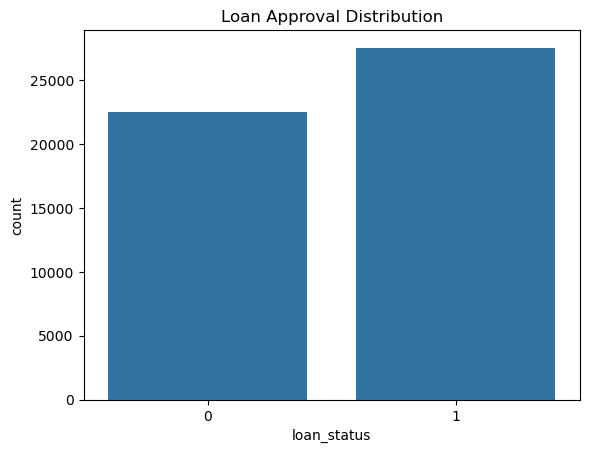

In [11]:
sns.countplot(x="loan_status", data=df)
plt.title("Loan Approval Distribution")
plt.show()

Loan can be seen roughly :
* 55% approved
* 45% rejected

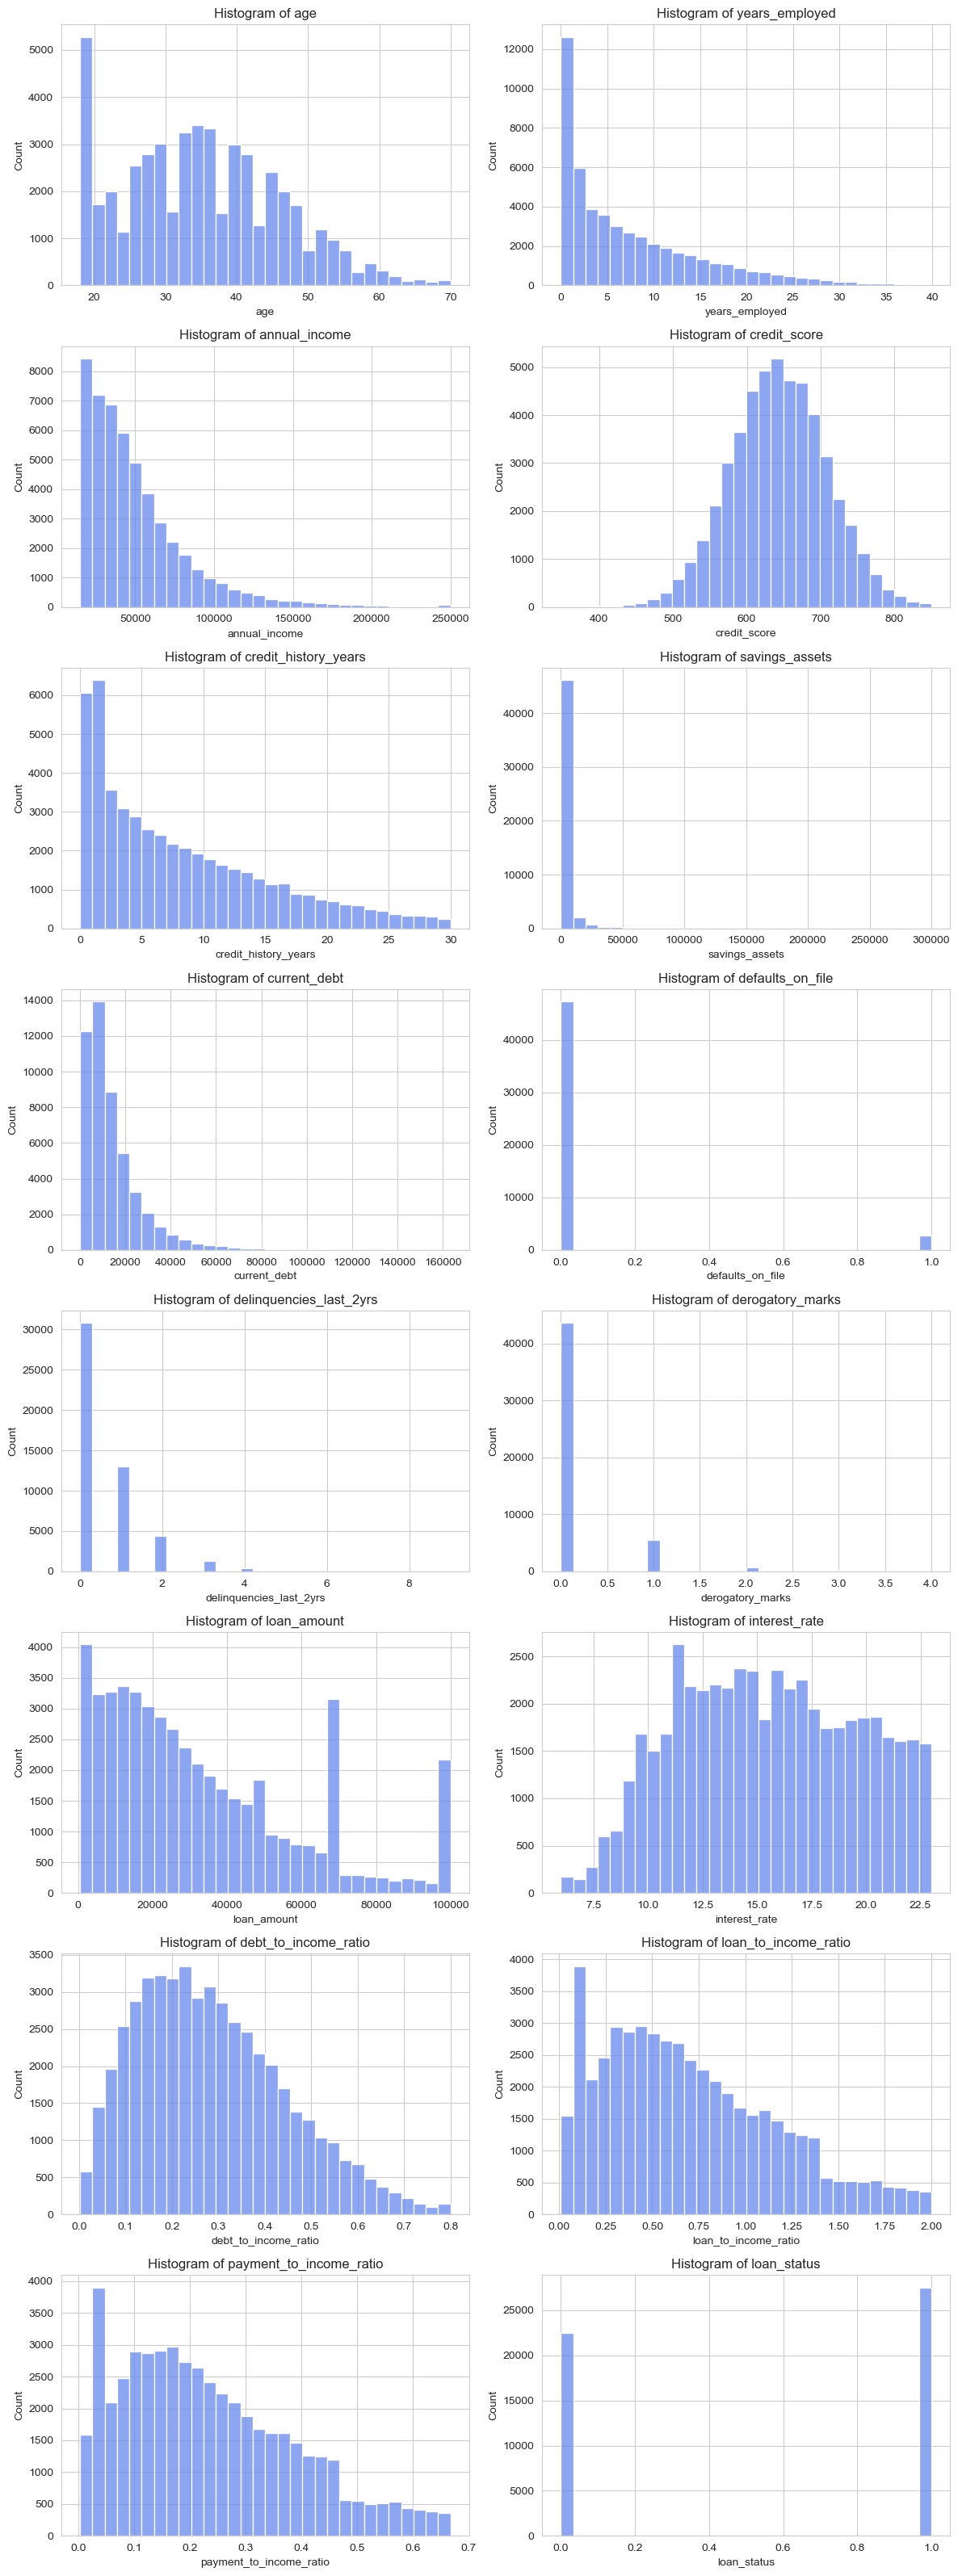

In [12]:
sns.set_style("whitegrid")
sns.set_palette("coolwarm")
n = len(numerical_col)
rows = (n + 1) // 2
plt.figure(figsize=(12, rows * 4))

for i, col in enumerate(numerical_col, 1):
    plt.subplot(rows, 2, i)
    sns.histplot(df[col], bins = 30)
    plt.title(f"Histogram of {col}")

plt.tight_layout()
plt.show()

In [13]:
for col in numerical_col:
    display(df[col].describe().reset_index())
    print('-'*70)

,index,age
0,count,50000.000000
1,mean,34.957060
2,std,11.118603
3,min,18.000000
4,25%,26.000000
5,50%,35.000000
6,75%,43.000000
7,max,70.000000


----------------------------------------------------------------------


,index,years_employed
0,count,50000.000000
1,mean,7.454868
2,std,7.612097
3,min,0.000000
4,25%,1.300000
5,50%,4.900000
6,75%,11.400000
7,max,39.900000


----------------------------------------------------------------------


,index,annual_income
0,count,50000.000000
1,mean,50062.892040
2,std,32630.501014
3,min,15000.000000
4,25%,27280.500000
5,50%,41607.500000
6,75%,62723.250000
7,max,250000.000000


----------------------------------------------------------------------


... (22 outputs left out)

,index,payment_to_income_ratio
0,count,50000.000000
1,mean,0.233995
2,std,0.155268
3,min,0.003000
4,25%,0.111000
5,50%,0.207000
6,75%,0.337000
7,max,0.667000


----------------------------------------------------------------------


,index,loan_status
0,count,50000.000000
1,mean,0.550460
2,std,0.497452
3,min,0.000000
4,25%,0.000000
5,50%,1.000000
6,75%,1.000000
7,max,1.000000


----------------------------------------------------------------------


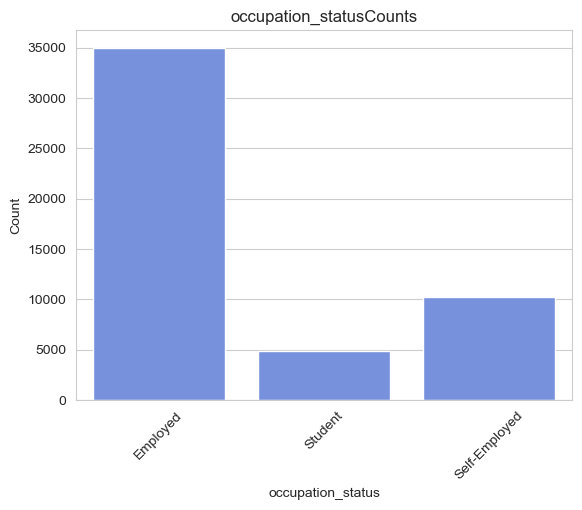

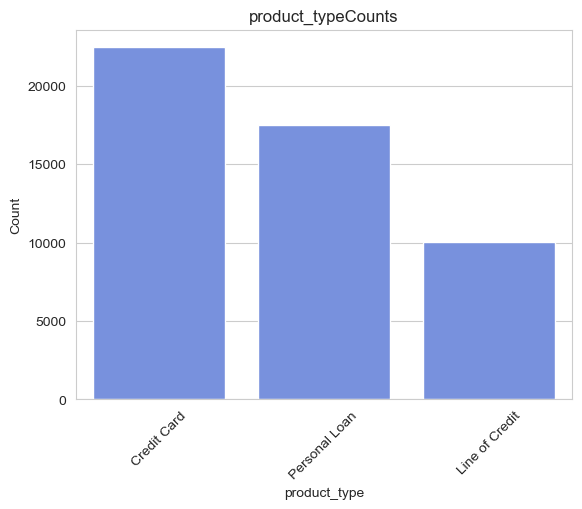

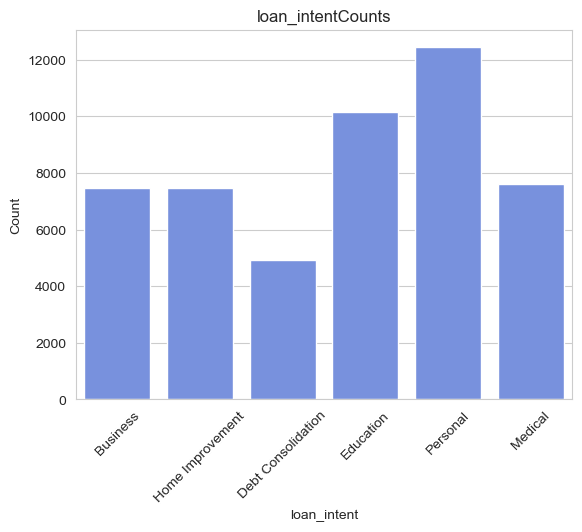

In [14]:
sns.set_style("whitegrid")
sns.set_palette("coolwarm")
for col in categorical_col:
    sns.countplot(x=df[col])
    plt.title(f"{col}Counts")
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.show()

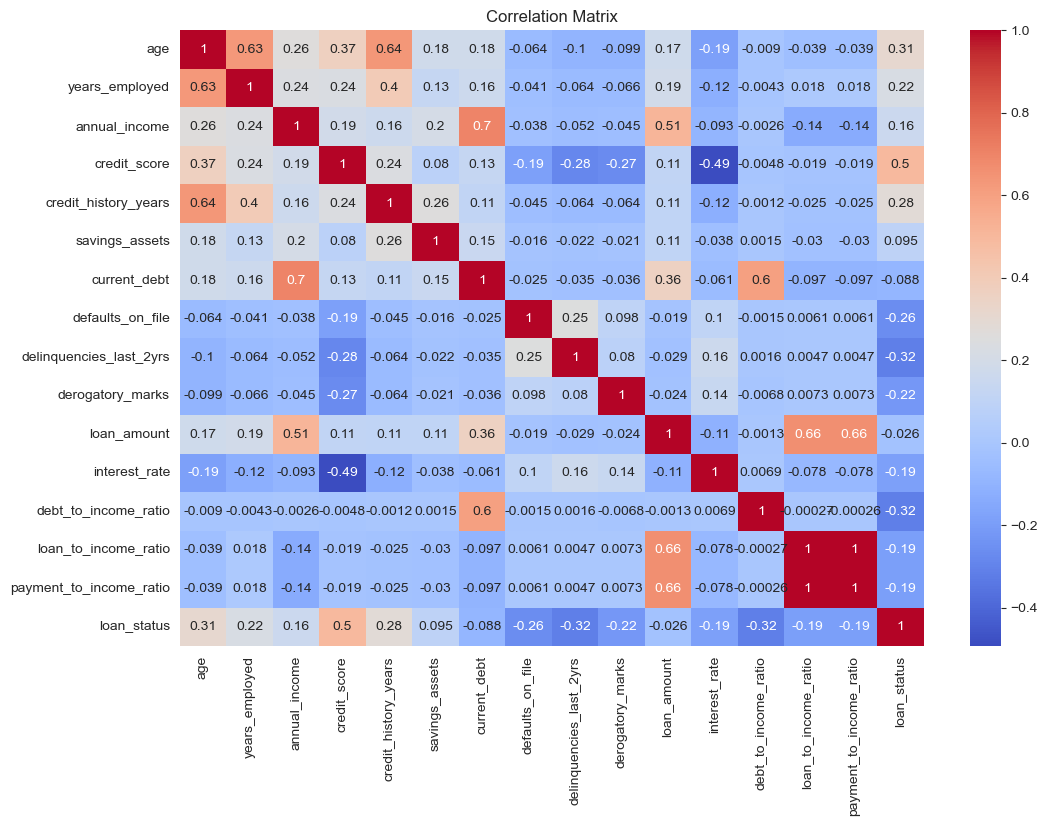

In [15]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

## Model Training

In [16]:
df = pd.get_dummies(df, drop_first=True)

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
import lightgbm as lgb

In [18]:
X = df.drop("loan_status", axis=1)
y = df["loan_status"]

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [20]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [21]:
log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_scaled, y_train)

lr_pred = log_model.predict(X_test_scaled)

lr_prob = log_model.predict_proba(X_test_scaled)[:, 1]

In [22]:
print("Logistic Regression Results")
print("Accuracy:", accuracy_score(y_test, lr_pred))
print("Precision:", precision_score(y_test, lr_pred))
print("Recall:", recall_score(y_test, lr_pred))
print("F1 Score:", f1_score(y_test, lr_pred))
print("ROC-AUC:", roc_auc_score(y_test, lr_prob))
print("\nClassification Report:\n", classification_report(y_test, lr_pred))

Logistic Regression Results
Accuracy: 0.8708
Precision: 0.8791764493407983
Recall: 0.8865416135494445
F1 Score: 0.8828436706565107
ROC-AUC: 0.9468784562040047

Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.85      0.86      4509
           1       0.88      0.89      0.88      5491

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000



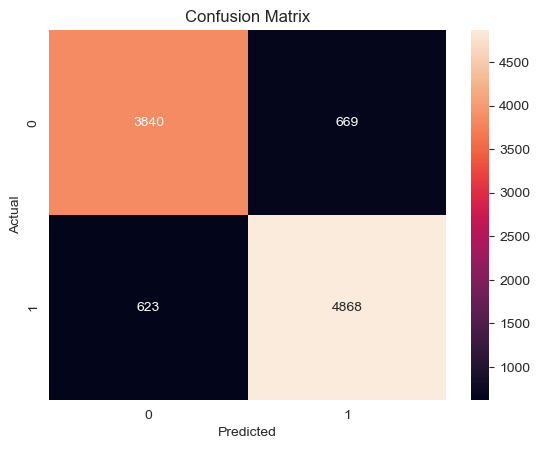

In [23]:
lr_cm = confusion_matrix(y_test, lr_pred)

sns.heatmap(lr_cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [24]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

In [25]:
print("Random Forest Results")
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))
print("\nClassification Report:\n", classification_report(y_test, rf_pred))

Random Forest Results
Accuracy: 0.9164
Precision: 0.9198989716759878
Recall: 0.9286104534693134
F1 Score: 0.9242341852456045
ROC-AUC: 0.9754108206420482

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.90      0.91      4509
           1       0.92      0.93      0.92      5491

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000



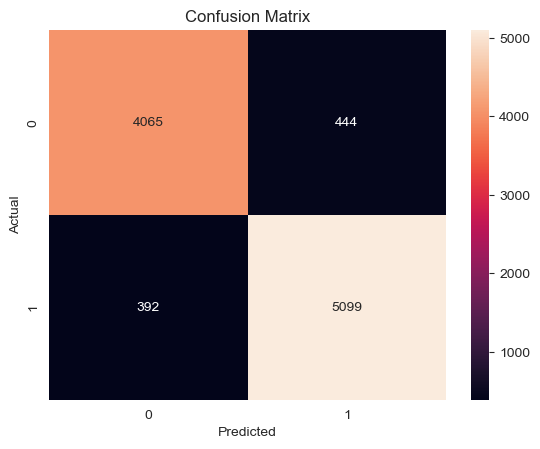

In [26]:
rf_cm = confusion_matrix(y_test, rf_pred)

sns.heatmap(rf_cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [27]:
lgb_model = lgb.LGBMClassifier(
    random_state=42,
    n_estimators=200,
    learning_rate=0.05
)

lgb_model.fit(X_train, y_train)
lgb_pred = lgb_model.predict(X_test)
lgb_prob = lgb_model.predict_proba(X_test)[:, 1]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 22032, number of negative: 17968
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003923 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2892
[LightGBM] [Info] Number of data points in the train set: 40000, number of used features: 24
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.550800 -> initscore=0.203904
[LightGBM] [Info] Start training from score 0.203904


In [28]:
print("LightGBM Results")
print("Accuracy:", accuracy_score(y_test, lgb_pred))
print("Precision:", precision_score(y_test, lgb_pred))
print("Recall:", recall_score(y_test, lgb_pred))
print("F1 Score:", f1_score(y_test, lgb_pred))
print("ROC-AUC:", roc_auc_score(y_test, lgb_prob))
print("\nClassification Report:\n", classification_report(y_test, lgb_pred))

LightGBM Results
Accuracy: 0.9333
Precision: 0.9372733865119652
Recall: 0.9415407029684939
F1 Score: 0.9394021986008904
ROC-AUC: 0.9857068073125487

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.92      0.93      4509
           1       0.94      0.94      0.94      5491

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



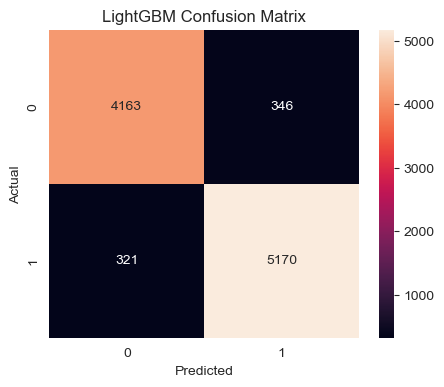

In [29]:
lgb_cm = confusion_matrix(y_test, lgb_pred)

plt.figure(figsize=(5,4))
sns.heatmap(lgb_cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("LightGBM Confusion Matrix")
plt.show()

In [30]:
xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

In [31]:
print("XGBoost Results")
print("Accuracy:", accuracy_score(y_test, xgb_pred))
print("Precision:", precision_score(y_test, xgb_pred))
print("Recall:", recall_score(y_test, xgb_pred))
print("F1 Score:", f1_score(y_test, xgb_pred))
print("ROC-AUC:", roc_auc_score(y_test, xgb_prob))
print("\nClassification Report:\n", classification_report(y_test, xgb_pred))

XGBoost Results
Accuracy: 0.9317
Precision: 0.9319080129356809
Recall: 0.9446366782006921
F1 Score: 0.9382291760875463
ROC-AUC: 0.9848585069485465

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.92      0.92      4509
           1       0.93      0.94      0.94      5491

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



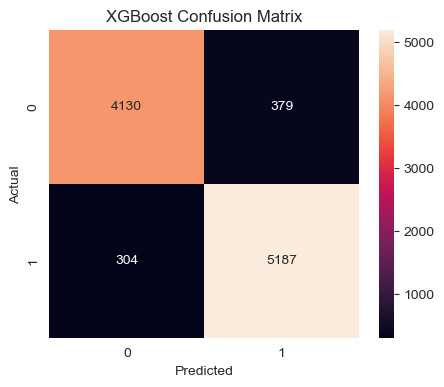

In [32]:
xgb_cm = confusion_matrix(y_test, xgb_pred)

plt.figure(figsize=(5,4))
sns.heatmap(xgb_cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost Confusion Matrix")
plt.show()

In [33]:
cat_model = CatBoostClassifier(
    iterations=200,
    learning_rate=0.05,
    depth=6,
    random_state=42,
    verbose=0   # suppress training output
)

cat_model.fit(X_train, y_train)

cat_pred = cat_model.predict(X_test)
cat_prob = cat_model.predict_proba(X_test)[:,1]

In [34]:
print("CatBoost Results")
print("Accuracy:", accuracy_score(y_test, cat_pred))
print("Precision:", precision_score(y_test, cat_pred))
print("Recall:", recall_score(y_test, cat_pred))
print("F1 Score:", f1_score(y_test, cat_pred))
print("ROC-AUC:", roc_auc_score(y_test, cat_prob))

print("\nClassification Report:\n", classification_report(y_test, cat_pred))

CatBoost Results
Accuracy: 0.9307
Precision: 0.9293128131710809
Recall: 0.9457293753414678
F1 Score: 0.9374492282696995
ROC-AUC: 0.9838994586152973

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.91      0.92      4509
           1       0.93      0.95      0.94      5491

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



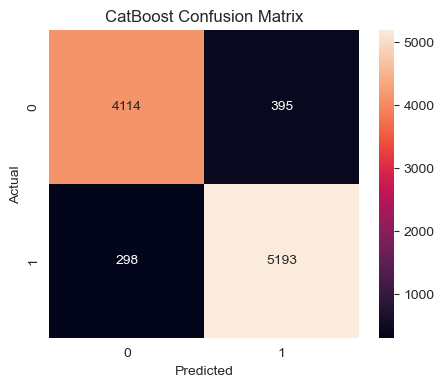

In [35]:
cat_cm = confusion_matrix(y_test, cat_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cat_cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CatBoost Confusion Matrix")
plt.show()

In [36]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "LightGBM", "XGBoost", "CatBoost"],
    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, lgb_pred),
        accuracy_score(y_test, xgb_pred),
        accuracy_score(y_test, cat_pred)
    ],
    "Precision": [
        precision_score(y_test, lr_pred),
        precision_score(y_test, rf_pred),
        precision_score(y_test, lgb_pred),
        precision_score(y_test, xgb_pred),
        precision_score(y_test, cat_pred)
    ],
    "Recall": [
        recall_score(y_test, lr_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test, lgb_pred),
        recall_score(y_test, xgb_pred),
        recall_score(y_test, cat_pred)
    ],
    "F1 Score": [
        f1_score(y_test, lr_pred),
        f1_score(y_test, rf_pred),
        f1_score(y_test, lgb_pred),
        f1_score(y_test, xgb_pred),
        f1_score(y_test, cat_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, lr_prob),
        roc_auc_score(y_test, rf_prob),
        roc_auc_score(y_test, lgb_prob),
        roc_auc_score(y_test, xgb_prob),
        roc_auc_score(y_test, cat_prob)
    ]
})

results.sort_values(by="ROC-AUC", ascending=False)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,LightGBM,0.9333,0.937273,0.941541,0.939402,0.985707
3,XGBoost,0.9317,0.931908,0.944637,0.938229,0.984859
4,CatBoost,0.9307,0.929313,0.945729,0.937449,0.983899
1,Random Forest,0.9164,0.919899,0.928610,0.924234,0.975411
0,Logistic Regression,0.8708,0.879176,0.886542,0.882844,0.946878


* **LightGBM** achieved the **best overall performance** across all evaluation metrics, including accuracy, F1 score, and ROC-AUC, indicating its strong capability in handling the loan risk prediction task.
* **XGBoost** and **CatBoost** also performed competitively, with both models achieving high recall values. This suggests that they are highly effective in identifying high-risk applicants, which is critical in minimizing loan defaults.
* Among the three boosting models, **LightGBM** provides a better balance between precision and recall, while **CatBoost** demonstrates comparable classification performance but slightly lower ROC-AUC, indicating a marginally weaker ranking ability in distinguishing between classes.
* **Random Forest** showed solid performance but was slightly inferior to the boosting models, while **Logistic Regression**, as a baseline model, achieved the lowest performance, highlighting the advantage of ensemble and boosting techniques in capturing complex patterns in the dataset.

### Hyperparameter Tuning

In [37]:
from sklearn.model_selection import RandomizedSearchCV

#### Random Forest Hyperparameter Tuning

In [38]:
rf_model = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

param_dist_rf = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"],
    "bootstrap": [True, False],
    "class_weight": [None, "balanced"]
}

random_rf = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_dist_rf,
    n_iter=20,
    scoring="roc_auc",
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

random_rf.fit(X_train, y_train)

best_rf = random_rf.best_estimator_

print("Best Parameters (Random Forest):", random_rf.best_params_)
print("Best ROC-AUC (CV):", random_rf.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Parameters (Random Forest): {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': None, 'class_weight': None, 'bootstrap': False}
Best ROC-AUC (CV): 0.9724396179390631


#### LightGBM Hyperparameter Tuning

In [39]:
lgb_model = lgb.LGBMClassifier(random_state=42)

param_dist_lgb = {
    'num_leaves': [31, 50, 70],
    'max_depth': [-1, 6, 10, 15],
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 200, 300],
    'min_child_samples': [20, 30, 50],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0]
}

random_lgb = RandomizedSearchCV(
    estimator=lgb_model,
    param_distributions=param_dist_lgb,
    n_iter=20,
    scoring='roc_auc',
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

random_lgb.fit(X_train, y_train)

best_lgb = random_lgb.best_estimator_

print("Best Parameters (LightGBM):", random_lgb.best_params_)
print("Best ROC-AUC (CV):", random_lgb.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 22032, number of negative: 17968
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.007412 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2892
[LightGBM] [Info] Number of data points in the train set: 40000, number of used features: 24
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.550800 -> initscore=0.203904
[LightGBM] [Info] Start training from score 0.203904
Best Parameters (LightGBM): {'subsample': 0.9, 'num_leaves': 31, 'n_estimators': 200, 'min_child_samples': 50, 'max_depth': 15, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
Best ROC-AUC (CV): 0.9833200256580316


#### XGBoost Hyperparameter Tuning

In [40]:
xgb_model = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

param_dist_xgb = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [4, 6, 8, 10],
    'min_child_weight': [1, 3, 5],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0],
    'gamma': [0, 0.1, 0.3]
}

random_xgb = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_dist_xgb,
    n_iter=20,
    scoring='roc_auc',
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=1
)

random_xgb.fit(X_train, y_train)

best_xgb = random_xgb.best_estimator_

print("Best Parameters (XGBoost):", random_xgb.best_params_)
print("Best ROC-AUC (CV):", random_xgb.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Parameters (XGBoost): {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.1, 'gamma': 0.1, 'colsample_bytree': 0.9}
Best ROC-AUC (CV): 0.9836177400869994


#### CatBoost Hyperparameter Tuning

In [41]:
cat_model = CatBoostClassifier(
    random_state=42,
    verbose=0
)

param_dist_cat = {
    'iterations': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'depth': [4, 6, 8, 10],
    'l2_leaf_reg': [1, 3, 5, 7, 9],
    'border_count': [32, 64, 128]
}

random_cat = RandomizedSearchCV(
    estimator=cat_model,
    param_distributions=param_dist_cat,
    n_iter=20,
    scoring='roc_auc',
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

random_cat.fit(X_train, y_train)

best_cat = random_cat.best_estimator_

print("Best Parameters (CatBoost):", random_cat.best_params_)
print("Best ROC-AUC (CV):", random_cat.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Parameters (CatBoost): {'learning_rate': 0.1, 'l2_leaf_reg': 5, 'iterations': 200, 'depth': 4, 'border_count': 128}
Best ROC-AUC (CV): 0.9835707061638826


In [42]:
def evaluate_model(model, X_test, y_test, model_name):
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    print(f"\n{model_name} Results After Tuning")
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred))
    print("Recall:", recall_score(y_test, pred))
    print("F1 Score:", f1_score(y_test, pred))
    print("ROC-AUC:", roc_auc_score(y_test, prob))
    print("\nClassification Report:\n", classification_report(y_test, pred))

In [43]:
evaluate_model(best_rf, X_test, y_test, "Random Forest")
evaluate_model(best_lgb, X_test, y_test, "LightGBM")
evaluate_model(best_xgb, X_test, y_test, "XGBoost")
evaluate_model(best_cat, X_test, y_test, "CatBoost")


Random Forest Results After Tuning
Accuracy: 0.9163
Precision: 0.9182242990654206
Recall: 0.9304316153706065
F1 Score: 0.9242876526458615
ROC-AUC: 0.9762047567585643

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.90      0.91      4509
           1       0.92      0.93      0.92      5491

    accuracy                           0.92     10000
   macro avg       0.92      0.91      0.92     10000
weighted avg       0.92      0.92      0.92     10000


LightGBM Results After Tuning
Accuracy: 0.9334
Precision: 0.9363356845722554
Recall: 0.942815516299399
F1 Score: 0.9395644283121597
ROC-AUC: 0.985684875821921

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.92      0.93      4509
           1       0.94      0.94      0.94      5491

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93 

In [63]:
performance_df = pd.DataFrame({
    "Model": ["Random Forest", "LightGBM", "XGBoost", "CatBoost"],
    "Accuracy": [
        accuracy_score(y_test, best_rf.predict(X_test)),
        accuracy_score(y_test, best_lgb.predict(X_test)),
        accuracy_score(y_test, best_xgb.predict(X_test)),
        accuracy_score(y_test, best_cat.predict(X_test))
    ],
    "Precision": [
        precision_score(y_test, best_rf.predict(X_test)),
        precision_score(y_test, best_lgb.predict(X_test)),
        precision_score(y_test, best_xgb.predict(X_test)),
        precision_score(y_test, best_cat.predict(X_test))
    ],
    "Recall": [
        recall_score(y_test, best_rf.predict(X_test)),
        recall_score(y_test, best_lgb.predict(X_test)),
        recall_score(y_test, best_xgb.predict(X_test)),
        recall_score(y_test, best_cat.predict(X_test))
    ],
    "F1-Score": [
        f1_score(y_test, best_rf.predict(X_test)),
        f1_score(y_test, best_lgb.predict(X_test)),
        f1_score(y_test, best_xgb.predict(X_test)),
        f1_score(y_test, best_cat.predict(X_test))
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, best_rf.predict_proba(X_test)[:,1]),
        roc_auc_score(y_test, best_lgb.predict_proba(X_test)[:,1]),
        roc_auc_score(y_test, best_xgb.predict_proba(X_test)[:,1]),
        roc_auc_score(y_test, best_cat.predict_proba(X_test)[:,1])
    ]
})

performance_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.9163,0.918224,0.930432,0.924288,0.976205
1,LightGBM,0.9334,0.936336,0.942816,0.939564,0.985685
2,XGBoost,0.9327,0.932651,0.945729,0.939145,0.985463
3,CatBoost,0.9336,0.933849,0.946094,0.939931,0.985250


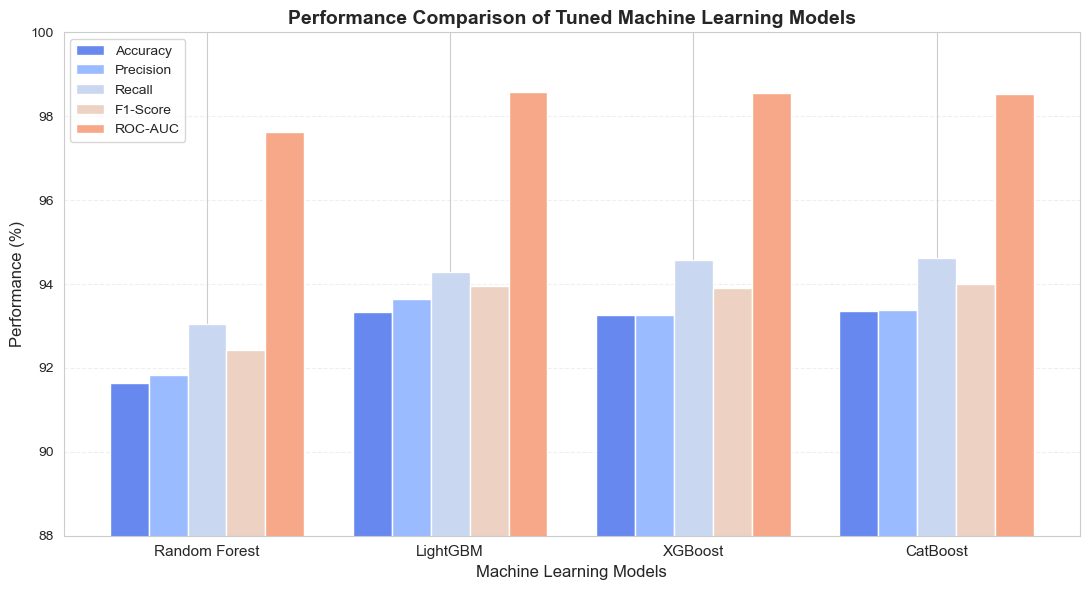

In [64]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

x = np.arange(len(performance_df))
width = 0.16

plt.figure(figsize=(11,6))

for i, metric in enumerate(metrics):
    plt.bar(
        x + (i-2)*width,
        performance_df[metric]*100,
        width,
        label=metric
    )

plt.xticks(x, performance_df["Model"], fontsize=11)
plt.ylabel("Performance (%)", fontsize=12)
plt.xlabel("Machine Learning Models", fontsize=12)
plt.title("Performance Comparison of Tuned Machine Learning Models", fontsize=14, weight='bold')

plt.ylim(88,100)

plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.legend()

plt.tight_layout()

plt.savefig("Performance_Comparison_Tuned.png",
            dpi=300,
            bbox_inches='tight')

plt.show()

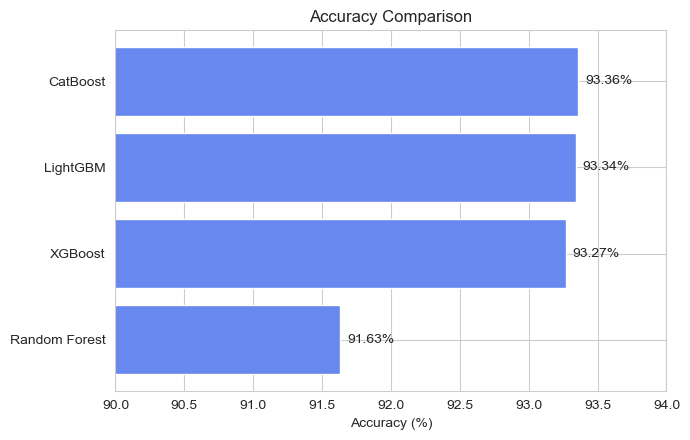

In [65]:
plot_df = performance_df.sort_values("Accuracy")

plt.figure(figsize=(7,4.5))

bars = plt.barh(
    plot_df["Model"],
    plot_df["Accuracy"]*100
)

plt.xlim(90,94)

plt.xlabel("Accuracy (%)")
plt.title("Accuracy Comparison")

for bar in bars:

    value = bar.get_width()

    plt.text(
        value+0.05,
        bar.get_y()+bar.get_height()/2,
        f"{value:.2f}%",
        va='center',
        fontsize=10
    )

plt.tight_layout()

plt.savefig("Accuracy_Comparison.png",
            dpi=300,
            bbox_inches='tight')

plt.show()

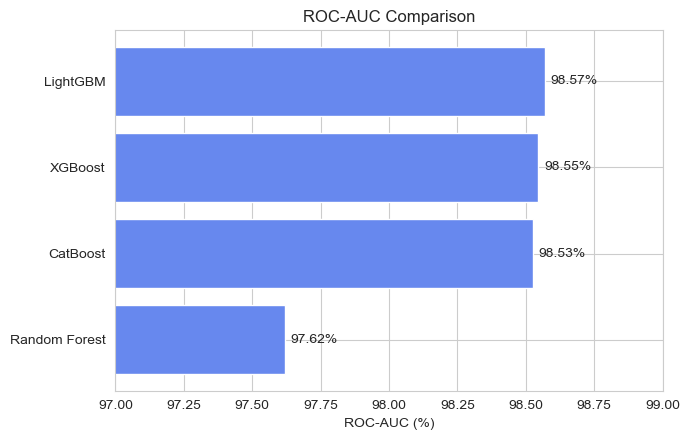

In [66]:
plt.figure(figsize=(7,4.5))

plot_df = performance_df.sort_values("ROC-AUC")

bars = plt.barh(
    plot_df["Model"],
    plot_df["ROC-AUC"]*100
)

plt.xlim(97,99)

plt.xlabel("ROC-AUC (%)")
plt.title("ROC-AUC Comparison")

for bar in bars:

    value = bar.get_width()

    plt.text(
        value+0.02,
        bar.get_y()+bar.get_height()/2,
        f"{value:.2f}%",
        va='center',
        fontsize=10
    )

plt.tight_layout()

plt.savefig("ROC_AUC_Comparison.png",
            dpi=300,
            bbox_inches='tight')

plt.show()

After hyperparameter tuning using RandomizedSearchCV, all models show strong and improved performance on the test dataset. Gradient boosting models consistently outperform traditional approaches, with LightGBM achieving the highest ROC-AUC (0.9857), followed closely by XGBoost (0.9849) and CatBoost (0.9839). CatBoost records the highest accuracy (0.9336), while LightGBM provides the best overall discrimination ability. 

Overall, the tuned models demonstrate high predictive performance, with boosting-based methods providing the most reliable results.

### Feature Importance

Feature	Meaning
* credit_score - borrower creditworthiness
* debt_to_income_ratio - repayment capacity
* credit_history_years - financial stability
* years_employed - income stability
* loan_to_income_ratio - loan burden
* loan_intent_Education - lower risk loans
* loan_amount - exposure
* delinquencies_last_2yrs - past risk behaviour
* interest_rate - risk pricing
* loan_intent_Personal - moderate risk



In [44]:
def plot_feature_importance(model, feature_names, model_name, top_n=15):
    # Get feature importance
    importances = model.feature_importances_
    
    # Create dataframe
    fi_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importances
    })
    
    # Sort descending
    fi_df = fi_df.sort_values(by='Importance', ascending=False).reset_index(drop=True)
    
    # Keep top N
    fi_top = fi_df.head(top_n)
    
    # Plot
    plt.figure(figsize=(8, 5))
    sns.barplot(data=fi_top, x='Importance', y='Feature')
    plt.title(f'{model_name} Feature Importance (Top {top_n})')
    plt.xlabel('Importance')
    plt.ylabel('Feature')
    plt.tight_layout()
    plt.show()
    
    return fi_df

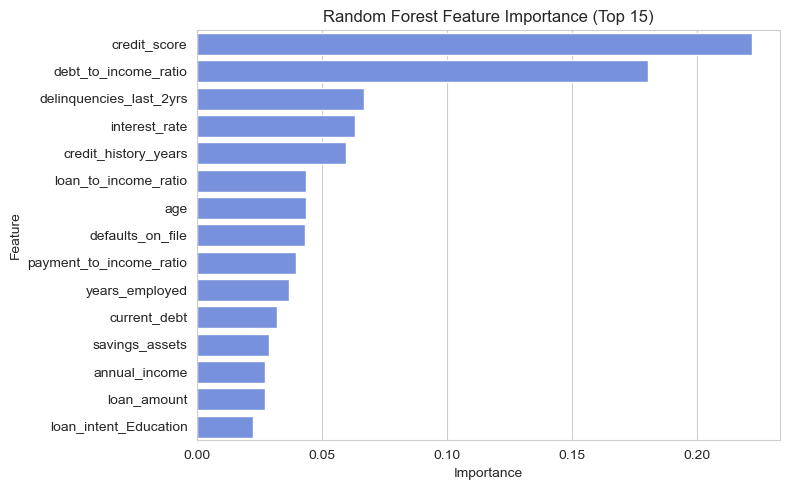

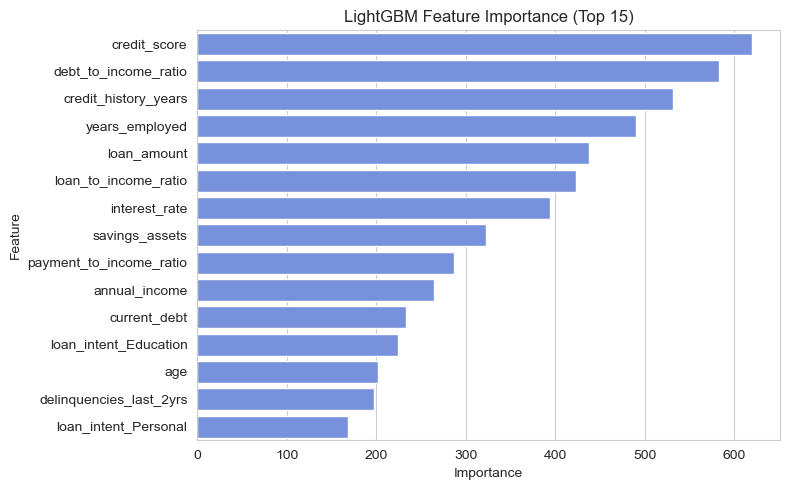

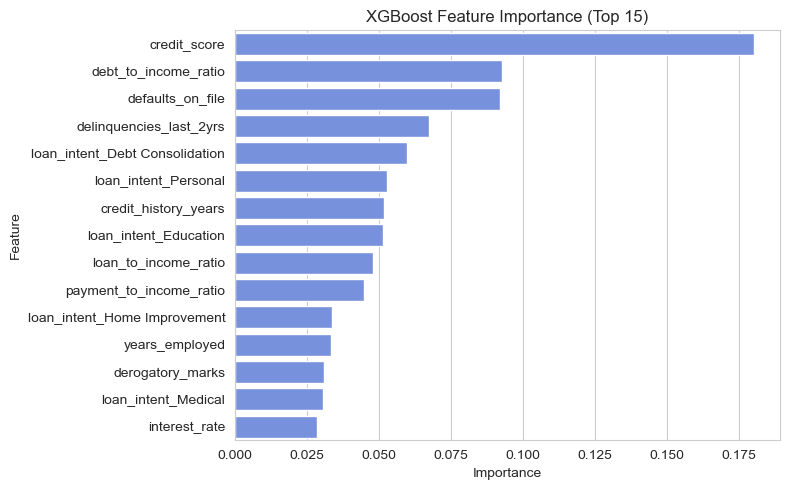

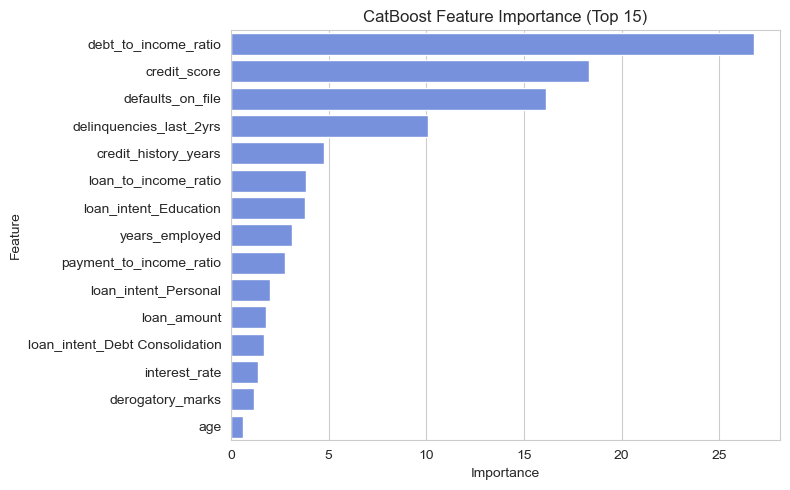

In [45]:
feature_names = X_train.columns

rf_fi = plot_feature_importance(best_rf, feature_names, "Random Forest", top_n=15)
lgb_fi = plot_feature_importance(best_lgb, feature_names, "LightGBM", top_n=15)
xgb_fi = plot_feature_importance(best_xgb, feature_names, "XGBoost", top_n=15)
cat_fi = plot_feature_importance(best_cat, feature_names, "CatBoost", top_n=15)

In [46]:
top_n = 10

rf_top = set(rf_fi.head(top_n)['Feature'])
lgb_top = set(lgb_fi.head(top_n)['Feature'])
xgb_top = set(xgb_fi.head(top_n)['Feature'])
cat_top = set(cat_fi.head(top_n)['Feature'])

In [47]:
from collections import Counter

all_features = list(rf_top) + list(lgb_top) + list(xgb_top) + list(cat_top)

feature_counts = Counter(all_features)

important_features = sorted(feature_counts.items(), key=lambda x: x[1], reverse=True)

print("Feature Importance Frequency Across Models:")
for feature, count in important_features:
    print(f"{feature}: {count}/4 models")

Feature Importance Frequency Across Models:
payment_to_income_ratio: 4/4 models
debt_to_income_ratio: 4/4 models
credit_score: 4/4 models
credit_history_years: 4/4 models
loan_to_income_ratio: 4/4 models
years_employed: 3/4 models
defaults_on_file: 3/4 models
delinquencies_last_2yrs: 3/4 models
interest_rate: 2/4 models
loan_intent_Education: 2/4 models
loan_intent_Personal: 2/4 models
age: 1/4 models
annual_income: 1/4 models
loan_amount: 1/4 models
savings_assets: 1/4 models
loan_intent_Debt Consolidation: 1/4 models


Feature importance analysis was conducted using Random Forest, LightGBM, XGBoost, and CatBoost to identify the most influential variables in predicting loan default risk. The comparison allows evaluation of feature stability across different machine learning algorithms.

#### Strongest Features (4/4 Models)
* credit_score
* loan_to_income_ratio
* debt_to_income_ratio
* payment_to_income_ratio
* credit_history_years

These features consistently appear across all four models, indicating they are the most reliable predictors of loan default risk. They mainly represent an applicant’s creditworthiness and financial burden. In particular, **credit score** and **credit history** years reflect past repayment behavior, while the **three financial ratios** measure affordability and repayment capacity relative to income. This confirms that both historical credit behavior and current financial stress are critical determinants of loan risk.

#### Highly Important Features (3/4 Models)

* years_employed
* defaults_on_file
* delinquencies_last_2yrs


These features appear in most models and represent recent repayment behavior and employment stability. Applicants with **recent delinquencies** or **default history** are consistently identified as higher risk, while **stable employment** contributes positively to loan approval decisions.

#### Moderately Important Features (2/4 Models)
* interest_rate
* loan_intent_Education
* loan_intent_Personal

These variables show moderate influence across models. Loan intent appears to affect risk perception differently depending on the model, suggesting that borrowing purpose may indirectly reflect financial planning behaviour. Interest rate also contributes but is less stable compared to core financial indicators.

#### Less Consistent Features (1/4 Models)
* age
* annual_income
* savings_assets
* loan_amount
* loan_intent_Debt Consolidation

These features appear in only one model, indicating weaker and less stable predictive power. This suggests that absolute financial values (such as income or savings) are less informative compared to relative measures like financial ratios, which are more consistently used across all models.

Overall, the results demonstrate strong agreement across all models that credit history and financial ratio-based features are the most important predictors of loan default risk. The consistency of these features across different algorithms strengthens their reliability and confirms that machine learning models align closely with real-world financial risk assessment principles.

In [48]:
import joblib
import json

joblib.dump(best_xgb, "xgboost_loan_model.pkl")
joblib.dump(X_train.columns.tolist(), "model_columns.pkl")

metadata = {
    "model_name": "XGBoost Loan Risk Model",
    "target": "loan_status",
    "positive_class_meaning": "Approved",
    "negative_class_meaning": "Rejected",
    "selected_features_count": len(X_train.columns)
}

with open("model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

In [49]:
import pandas as pd
import joblib

model = joblib.load("xgboost_loan_model.pkl")
model_columns = joblib.load("model_columns.pkl")

def predict_loan(input_dict: dict):
    df_input = pd.DataFrame([input_dict])

    # Apply same encoding as training
    df_input = pd.get_dummies(df_input, drop_first=True)

    # Add missing columns
    for col in model_columns:
        if col not in df_input.columns:
            df_input[col] = 0

    # Remove unexpected columns and reorder
    df_input = df_input[model_columns]

    prob = model.predict_proba(df_input)[0, 1]
    pred = model.predict(df_input)[0]

    risk_level = (
        "Low Risk" if prob >= 0.75 else
        "Moderate Risk" if prob >= 0.50 else
        "High Risk"
    )

    return {
        "prediction": int(pred),
        "approval_probability": float(prob),
        "risk_level": risk_level
    }

sample = {
    "age": 35,
    "occupation_status": "Employed",
    "years_employed": 8,
    "annual_income": 60000,
    "credit_score": 720,
    "credit_history_years": 6,
    "savings_assets": 15000,
    "current_debt": 12000,
    "defaults_on_file": 0,
    "delinquencies_last_2yrs": 0,
    "derogatory_marks": 0,
    "product_type": "Personal Loan",
    "loan_intent": "Education",
    "loan_amount": 20000,
    "interest_rate": 8.5,
    "debt_to_income_ratio": 0.25,
    "loan_to_income_ratio": 0.33,
    "payment_to_income_ratio": 0.12
}

predict_loan(sample)

{'prediction': 1,
 'approval_probability': 0.9977967739105225,
 'risk_level': 'Low Risk'}

### SHAP Analysis

In [50]:
import shap
import numpy as np

shap.initjs()

C:\Users\tzery\anaconda3\envs\FYP\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [51]:
def get_shap_values(model, X_data, model_name):
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_data)

    if isinstance(shap_values, list):
        shap_values = shap_values[1]

    if hasattr(shap_values, "values"):
        shap_values = shap_values.values

    shap_values = np.array(shap_values)

    if shap_values.ndim == 3:
        shap_values = shap_values[:, :, 1]

    print(f"{model_name} SHAP values shape:", shap_values.shape)

    return explainer, shap_values

In [52]:
import xgboost as xgb

In [53]:
def get_xgb_shap_values_xgb_native(model, X_data, model_name="XGBoost"):
    # Convert test data to XGBoost DMatrix
    dmatrix = xgb.DMatrix(X_data)

    contribs = model.get_booster().predict(dmatrix, pred_contribs=True)

    # Remove last column because it is the bias/base value
    shap_values = contribs[:, :-1]

    print(f"{model_name} SHAP values shape:", shap_values.shape)

    return shap_values

In [54]:
X_shap = X_test.sample(n=1000, random_state=42)
X_shap_rf = X_test.sample(n=100, random_state=42)

In [55]:
lgb_explainer, lgb_shap_values = get_shap_values(best_lgb, X_shap, "LightGBM")
xgb_shap_values = get_xgb_shap_values_xgb_native(best_xgb, X_shap, "XGBoost")
cat_explainer, cat_shap_values = get_shap_values(best_cat, X_shap, "CatBoost")

C:\Users\tzery\anaconda3\envs\FYP\lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


LightGBM SHAP values shape: (1000, 24)
XGBoost SHAP values shape: (1000, 24)
CatBoost SHAP values shape: (1000, 24)


In [56]:
rf_explainer = shap.TreeExplainer(best_rf)
rf_shap_values = rf_explainer.shap_values(X_shap_rf, approximate=False)

if isinstance(rf_shap_values, list):
    rf_shap_values = rf_shap_values[1]

if hasattr(rf_shap_values, "values"):
    rf_shap_values = rf_shap_values.values

rf_shap_values = np.array(rf_shap_values)

if rf_shap_values.ndim == 3:
    rf_shap_values = rf_shap_values[:, :, 1]

print("Random Forest SHAP values shape:", rf_shap_values.shape)

Random Forest SHAP values shape: (100, 24)


### Random Forest SHAP summary plot

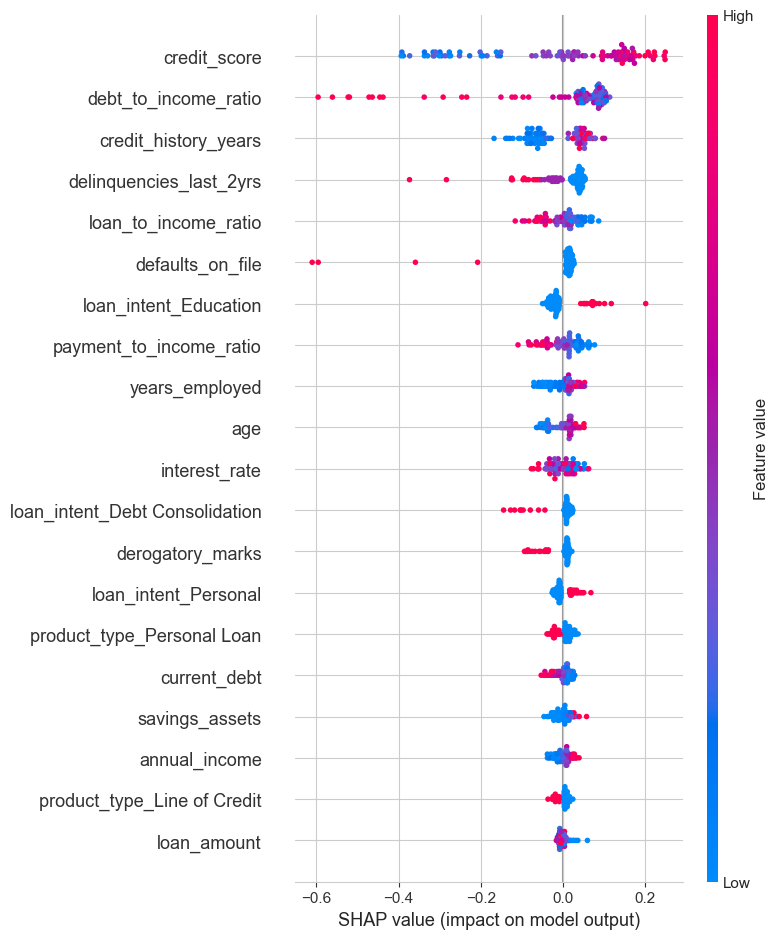

In [57]:
shap.summary_plot(rf_shap_values, X_shap_rf, show=True)

### LightGBM SHAP summary plot

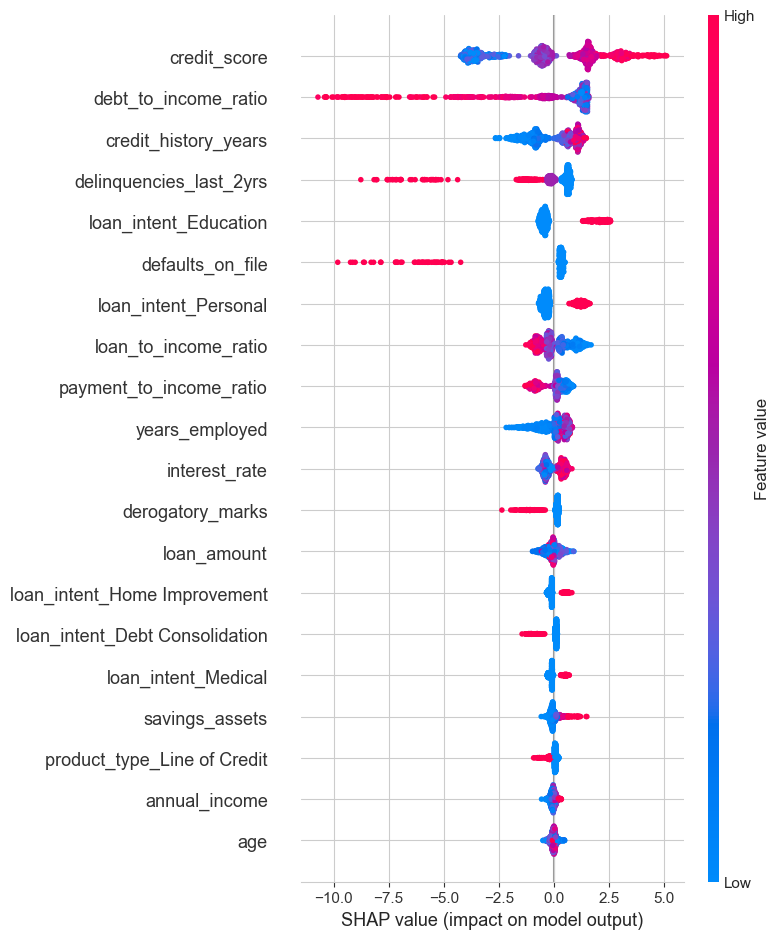

In [58]:
shap.summary_plot(lgb_shap_values, X_shap, show=True)

### XGBoost SHAP summary plot

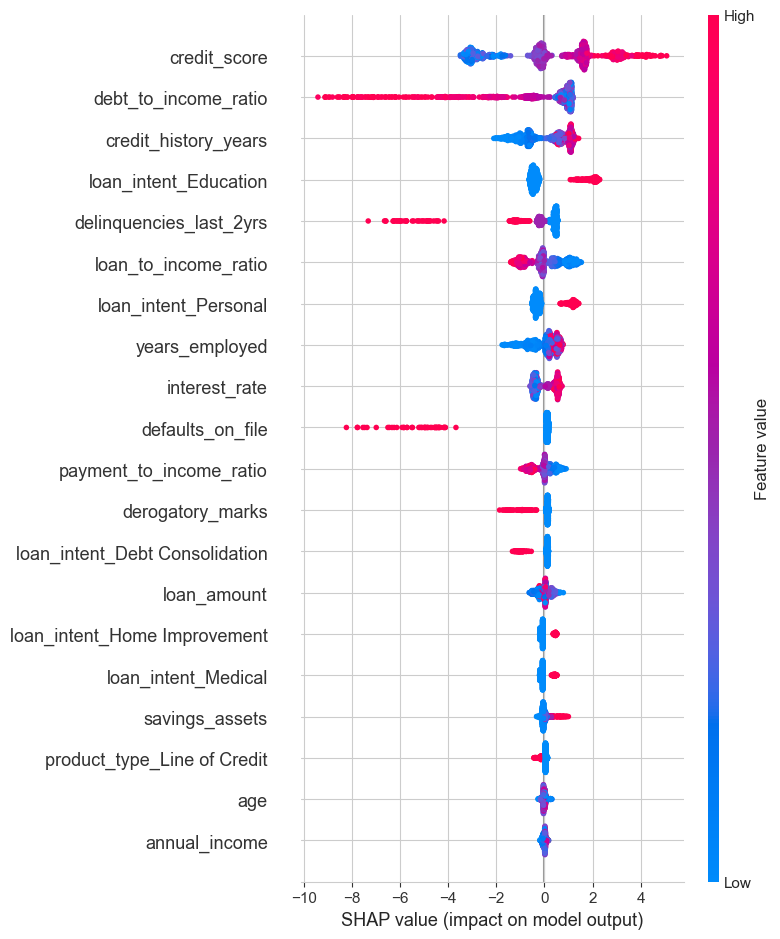

In [59]:
shap.summary_plot(xgb_shap_values, X_shap)

### CatBoost SHAP summary plot

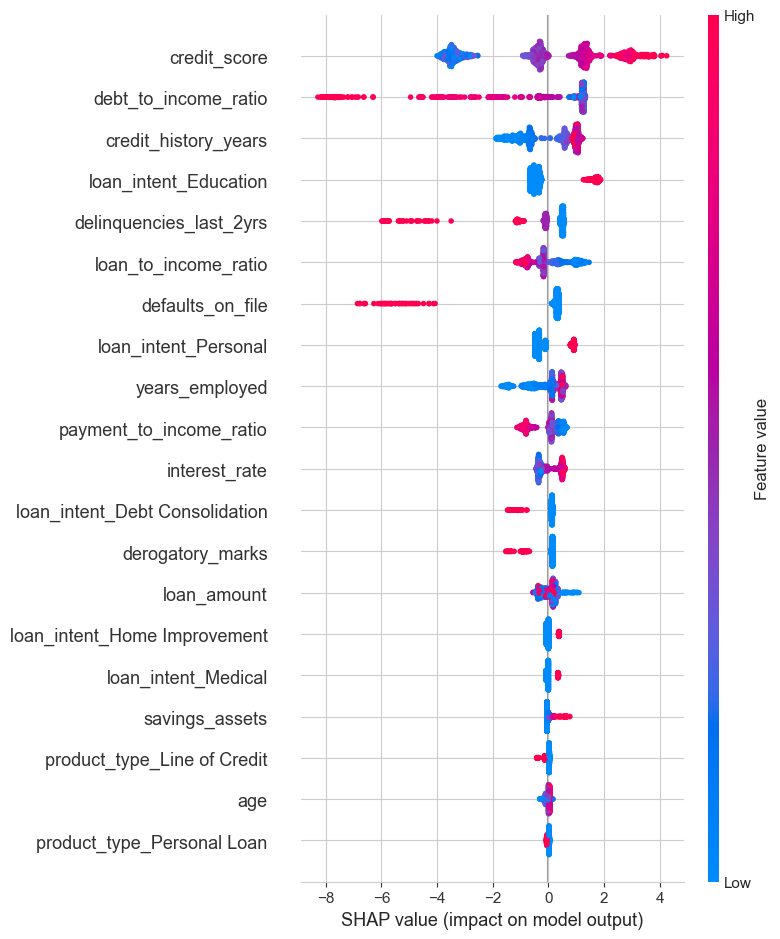

In [60]:
shap.summary_plot(cat_shap_values, X_shap, show=True)

In [61]:
def shap_importance_table(shap_values, X_data, model_name, top_n=10):
    importance = np.abs(shap_values).mean(axis=0)

    shap_df = pd.DataFrame({
        "Feature": X_data.columns,
        "Mean |SHAP|": importance,
        "Model": model_name
    }).sort_values(by="Mean |SHAP|", ascending=False)

    return shap_df.head(top_n)

rf_shap_importance = shap_importance_table(rf_shap_values, X_shap, "Random Forest")
lgb_shap_importance = shap_importance_table(lgb_shap_values, X_shap, "LightGBM")
xgb_shap_importance = shap_importance_table(xgb_shap_values, X_shap, "XGBoost")
cat_shap_importance = shap_importance_table(cat_shap_values, X_shap, "CatBoost")

all_shap_importance = pd.concat([
    rf_shap_importance,
    lgb_shap_importance,
    xgb_shap_importance,
    cat_shap_importance
])

all_shap_importance

,Feature,Mean |SHAP|,Model
3,credit_score,0.157738,Random Forest
12,debt_to_income_ratio,0.114397,Random Forest
4,credit_history_years,0.060823,Random Forest
8,delinquencies_last_2yrs,0.046239,Random Forest
13,loan_to_income_ratio,0.033699,Random Forest
7,defaults_on_file,0.032127,Random Forest
20,loan_intent_Education,0.032045,Random Forest
14,payment_to_income_ratio,0.030388,Random Forest
1,years_employed,0.025615,Random Forest
0,age,0.025047,Random Forest


#### Insights (SHAP Analysis)

* Applicants with higher credit scores significantly reduce the probability of default, confirming that past credit behavior is the strongest indicator of repayment reliability across all models.
* A higher debt-to-income ratio consistently increases default risk, indicating that applicants with heavier financial obligations relative to income are more likely to struggle with loan repayment.
* Longer credit history contributes to lower risk prediction, as it reduces uncertainty and reflects more stable and observable financial behavior over time.
* Financial ratio-based features (debt-to-income ratio, loan-to-income ratio, and payment-to-income ratio) consistently show stronger influence than absolute financial values, suggesting that the models prioritize relative financial burden over raw income or loan amount.
* Variables related to past repayment issues, such as delinquencies in the last two years and defaults on file, consistently contribute to higher predicted risk across all models, reinforcing the importance of historical credit behavior.
* Employment stability (years employed) also plays a moderate role in reducing risk, indicating that stable income sources improve model confidence in repayment ability.
* Loan intent features appear moderately influential, suggesting that borrowing purpose has some impact on risk prediction, but is less important compared to credit and financial indicators.

The SHAP analysis confirms that the machine learning models primarily rely on creditworthiness and financial stress indicators when making predictions. Relative financial measures have greater predictive power compared to absolute values, highlighting that repayment capacity is more important than income alone in assessing loan default risk.

Across all models, a consistent pattern is observed where strong credit history and low financial burden significantly reduce default risk, while past repayment issues and high debt levels increase risk.

#### Individual Prediction Sample for SHAP

In [62]:
shap.force_plot(
    explainer.expected_value,
    shap_values.values[0],
    X_test.iloc[0]
)

NameError: name 'explainer' is not defined

Key Observations:
* Positive contributors (increase approval / lower risk):
    * savings_assets = 8,397
    * credit_score = 679
    * credit_history_years = 11
    * low payment_to_income_ratio
<br></br>
* Negative contributors (increase risk):
    * delinquencies_last_2yrs = 2
    * interest_rate = 10.72
    * loan_intent_Personal

**Final prediction: 3.35** (leaning toward lower risk / approval)


Although the applicant has some risk factors such as recent delinquencies and a relatively high interest rate, the strong credit score, sufficient savings, and stable financial ratios outweigh these risks, resulting in a lower predicted default probability.



Conclusion:
* The SHAP analysis confirms that the model’s predictions are primarily driven by creditworthiness indicators and financial burden ratios. Features such as credit score, debt-related ratios, and repayment history consistently influence the prediction, demonstrating that the model aligns with real-world financial risk assessment principles.

In [ ]:
import joblib

joblib.dump(best_rf, "../model/random_forest_loan_model.pkl")
joblib.dump(best_xgb, "../model/xgboost_loan_model.pkl")
joblib.dump(best_lgb, "../model/lightgbm_loan_model.pkl")
joblib.dump(best_cat, "../model/catboost_loan_model.pkl")

joblib.dump(X_train.columns, "../model/model_columns.pkl")